In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [ ]:
df = pd.read_csv("train_cleaned.csv")

print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df['isFraud'].value_counts(normalize=True) * 100)

(590540, 338)
Missing values: 0
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


In [3]:
df['Amt_log'] = np.log1p(df['TransactionAmt'])
df['Amt_cents'] = df['TransactionAmt'] - np.floor(df['TransactionAmt'])

c_cols = [c for c in df.columns if c.startswith('C') and c[1:].isdigit()]
df['C_sum'] = df[c_cols].sum(axis=1)

null_cols = [c for c in df.columns if c.endswith('_isnull')]
df['Missing_count'] = df[null_cols].sum(axis=1)

print("Shape now:", df.shape)

Shape now: (590540, 342)


In [4]:
X = df.drop(columns=['isFraud'])
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Fraud % in train:", round(y_train.mean() * 100, 2))
print("Fraud % in test:", round(y_test.mean() * 100, 2))

Train: (472432, 341)
Test: (118108, 341)
Fraud % in train: 3.5
Fraud % in test: 3.5


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(sampling_strategy=0.5, random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_scaled, y_train)

print("\nAfter SMOTE:")
print(y_train_sm.value_counts())

Before SMOTE:
isFraud
0    455902
1     16530
Name: count, dtype: int64

After SMOTE:
isFraud
0    455902
1    227951
Name: count, dtype: int64


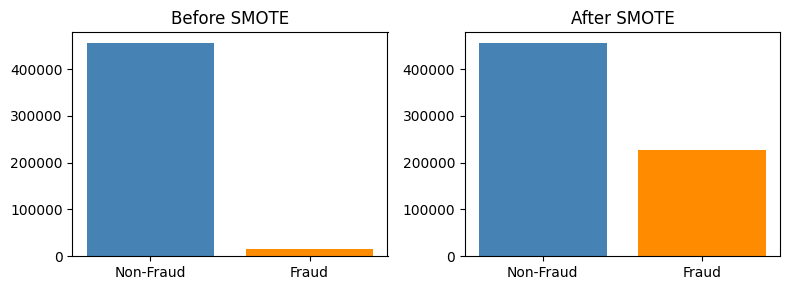

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].bar(['Non-Fraud', 'Fraud'], y_train.value_counts().sort_index().values, color=['steelblue', 'darkorange'])
ax[0].set_title('Before SMOTE')
ax[1].bar(['Non-Fraud', 'Fraud'], y_train_sm.value_counts().sort_index().values, color=['steelblue', 'darkorange'])
ax[1].set_title('After SMOTE')
plt.tight_layout()
plt.show()

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
    "SVM": LinearSVC(C=0.1, dual=False, max_iter=2000),
}

results = []
predictions = {}
scores = {}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_train_sm, y_train_sm)
    y_pred = model.predict(X_test_scaled)

    
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_score = model.decision_function(X_test_scaled)

    predictions[name] = y_pred
    scores[name] = y_score

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })

print("Done!")

Training Logistic Regression ...
Training Decision Tree ...
Training Random Forest ...
Training XGBoost ...
Training SVM ...
Done!


In [9]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost,0.9788,0.9035,0.4418,0.5934,0.9305
Random Forest,0.9757,0.7052,0.5260,0.6025,0.9180
Logistic Regression,0.9152,0.2296,0.6044,0.3327,0.8630
SVM,0.9222,0.2446,0.5853,0.3450,0.8617
Decision Tree,0.9476,0.3162,0.4278,0.3636,0.8188


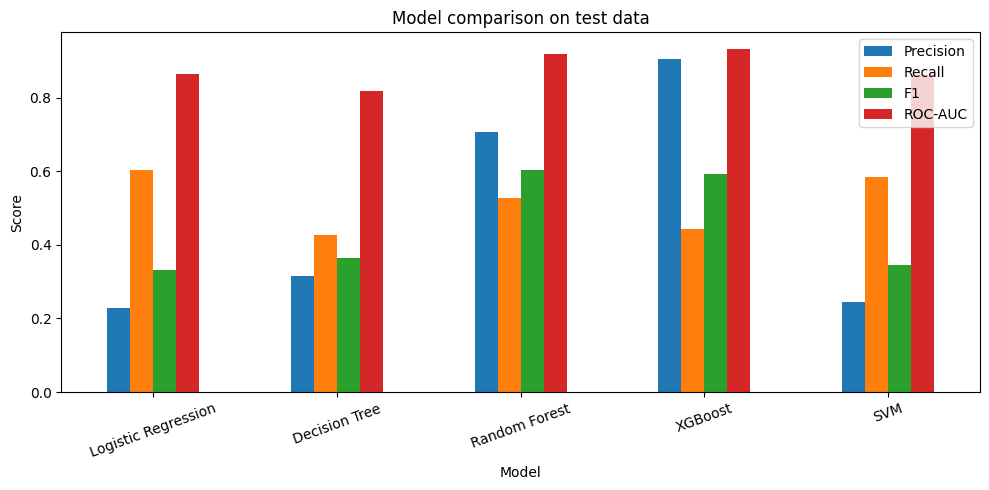

In [10]:
results_df[['Precision', 'Recall', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5))
plt.title('Model comparison on test data')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

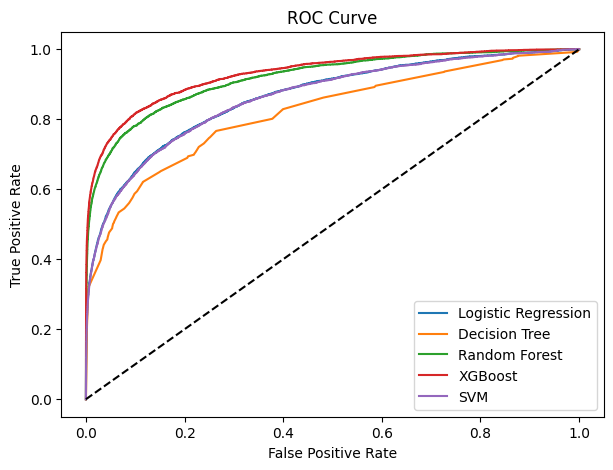

In [11]:
plt.figure(figsize=(7, 5))
for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

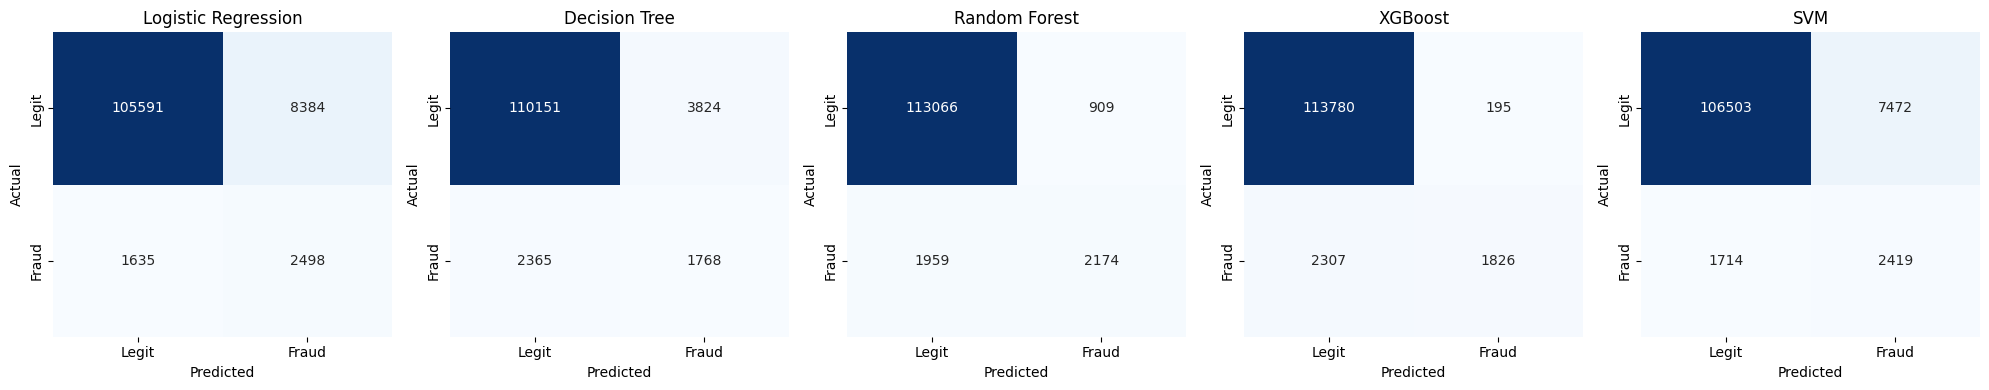

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()